# 🌍 La sous-nutrition dans le monde (2013-2017)

Analyse de quatre jeux de données de la FAO pour répondre à une question simple :
**produit-on assez de nourriture pour nourrir tout le monde, et où sont les personnes qui ont faim ?**

**Sommaire**
1. Données et unités
2. Q1 — Proportion de personnes sous-alimentées
3. Q2 — Nombre théorique de personnes nourries
4. Q3 — Idem avec les seuls produits végétaux
5. Q4 — Utilisation de la disponibilité intérieure
6. Q5 — Pays les plus touchés en 2017
7. Q6 — Pays ayant reçu le plus d'aide depuis 2013
8. Q7 — Pays ayant le plus et le moins de nourriture par habitant
9. Conclusion

> Les calculs sont regroupés dans `src/analysis.py` (testés avec `pytest`). Ce notebook les appelle et commente les résultats.

In [1]:
import sys
sys.path.insert(0, "..")

import matplotlib.pyplot as plt
import pandas as pd

from src import analysis as an

plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False, "font.size": 11})
RED, BLUE, GREEN, GREY, ORANGE = "#d1495b", "#2e86ab", "#3d9970", "#9aa0a6", "#edae49"

d = an.load_data()

## 1. Données et unités

| Fichier | Contenu | Unité de `Valeur` |
|---|---|---|
| `population.csv` | Population par pays, 2013-2018 | **milliers** d'habitants |
| `sous_nutrition.csv` | Personnes sous-alimentées, par période de 3 ans | **millions** de personnes |
| `dispo_alimentaire.csv` | Disponibilité alimentaire par pays et par produit (2017) | kcal/personne/jour, **milliers** de tonnes |
| `aide_alimentaire.csv` | Aide alimentaire reçue, 2013-2016 | **tonnes** |

⚠️ Deux pièges à éviter :
- Les unités sont différentes d'un fichier à l'autre : il faut tout convertir en **nombre de personnes** avant de comparer.
- Dans `sous_nutrition.csv`, les petits pays ont la valeur **`<0.1`** (moins de 100 000 personnes). Ce n'est pas un nombre : on ne l'invente pas, on l'exclut des calculs.

Convention : l'année **2017** correspond à la période **2016-2018**.

In [2]:
for name, df in [("population", d.population), ("sous_nutrition", d.sous_nutrition), ("dispo", d.dispo), ("aide", d.aide)]:
    print(f"{name:15s} {df.shape[0]:>6} lignes  {df.shape[1]:>2} colonnes")
d.sous_nutrition.head()

population        1416 lignes   3 colonnes
sous_nutrition    1218 lignes   4 colonnes
dispo            15605 lignes  18 colonnes
aide              1475 lignes   4 colonnes


,Zone,Année,Valeur,non_chiffre
0,Afghanistan,2012-2014,8.6,False
1,Afghanistan,2013-2015,8.8,False
2,Afghanistan,2014-2016,8.9,False
3,Afghanistan,2015-2017,9.7,False
4,Afghanistan,2016-2018,10.5,False


## 2. Q1 — Proportion de personnes sous-alimentées en 2017

In [3]:
q1 = an.q1_proportion(d)
print(f"Population mondiale 2017      : {an.billions(q1['population_mondiale'])}")
print(f"Personnes sous-alimentées     : {an.fr(q1['sous_alimentes'] / 1e6, 1)} millions")
print(f"Proportion                    : {an.pct(q1['proportion'])}")
print(f"Pays chiffrés : {q1['pays_chiffres']} · moins de 100 000 : {q1['pays_moins_de_100k']} · sans donnée : {q1['pays_sans_donnee']}")

Population mondiale 2017      : 7,55 milliards
Personnes sous-alimentées     : 535,7 millions
Proportion                    : 7,1 %
Pays chiffrés : 84 · moins de 100 000 : 20 · sans donnée : 99


**➜ Environ 7,1 % de la population mondiale, soit près de 536 millions de personnes, était en état de sous-nutrition en 2017.**

C'est une estimation basse : les pays notés `<0.1` et ceux sans donnée ne sont pas comptés.

## 3. Q2 — Combien de personnes pourrait-on nourrir ?

Méthode :
1. Pour chaque pays, on additionne les kcal/personne/jour de tous les produits.
2. On multiplie par la population du pays → **kcal disponibles chaque jour dans le pays**.
3. On additionne tous les pays, puis on divise par le **besoin d'une personne** : **2 500 kcal/jour** (hypothèse, à faire varier).

In [4]:
fed = an.people_fed(d)
print(f"Personnes qui pourraient être nourries : {an.billions(fed['personnes_nourries'])}")
print(f"Soit {an.pct(fed['part_population'], 0)} de la population mondiale ({fed['pays_utilises']} pays avec des données)")

needs = [2000, 2200, 2500, 2800]
sens = pd.DataFrame({"Besoin (kcal/jour)": needs,
                     "Personnes nourries (milliards)": [an.people_fed(d, kcal_need=k)["personnes_nourries"] / 1e9 for k in needs]})
sens.round(2)

Personnes qui pourraient être nourries : 8,37 milliards
Soit 111 % de la population mondiale (172 pays avec des données)


,Besoin (kcal/jour),Personnes nourries (milliards)
0,2000,10.46
1,2200,9.51
2,2500,8.37
3,2800,7.47


**➜ La nourriture disponible suffirait à nourrir 8,37 milliards de personnes, soit 111 % de la population mondiale.**
Même avec un besoin plus élevé de 2 700 kcal/jour, la production couvrirait encore 103 % de la population (le seuil se situe vers 2 770 kcal).
**Le problème de la faim n'est donc pas un problème de quantité, mais de répartition.**

## 4. Q3 — Et avec les seuls produits végétaux ?

Personnes nourries avec les produits végétaux : 6,90 milliards (91 %)


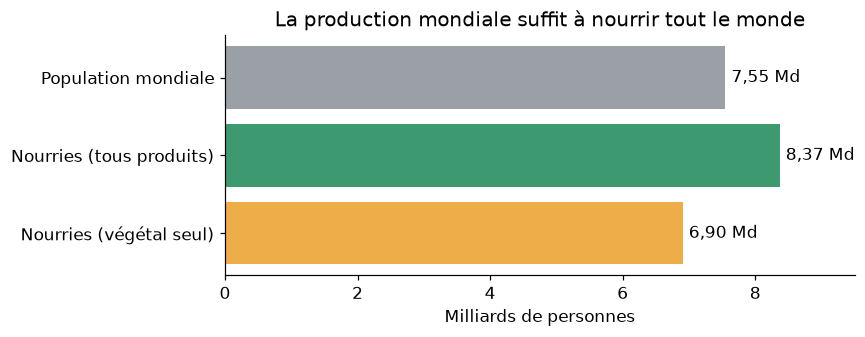

In [5]:
veg = an.people_fed(d, "vegetale")
print(f"Personnes nourries avec les produits végétaux : {an.billions(veg['personnes_nourries'])} ({an.pct(veg['part_population'], 0)})")

fig, ax = plt.subplots(figsize=(8, 3.2))
labels = ["Population mondiale", "Nourries (tous produits)", "Nourries (végétal seul)"]
values = [q1["population_mondiale"] / 1e9, fed["personnes_nourries"] / 1e9, veg["personnes_nourries"] / 1e9]
bars = ax.barh(labels, values, color=[GREY, GREEN, ORANGE])
ax.bar_label(bars, labels=[f"{an.fr(v, 2)} Md" for v in values], padding=4)
ax.invert_yaxis(); ax.set_xlabel("Milliards de personnes"); ax.set_xlim(0, 9.5)
ax.set_title("La production mondiale suffit à nourrir tout le monde")
plt.tight_layout(); plt.show()

**➜ Les produits végétaux seuls pourraient nourrir 6,9 milliards de personnes (91 % de la population).**

## 5. Q4 — À quoi sert la nourriture disponible ?

,Utilisation,Milliers de tonnes,Part
0,Alimentation humaine,4876258.0,"49,5 %"
1,"Transformation (huiles, sucre, boissons…)",2204687.0,"22,4 %"
2,Alimentation animale,1304245.0,"13,2 %"
3,Autres utilisations,865023.0,"8,8 %"
4,Pertes,453698.0,"4,6 %"
5,Semences,154681.0,"1,6 %"


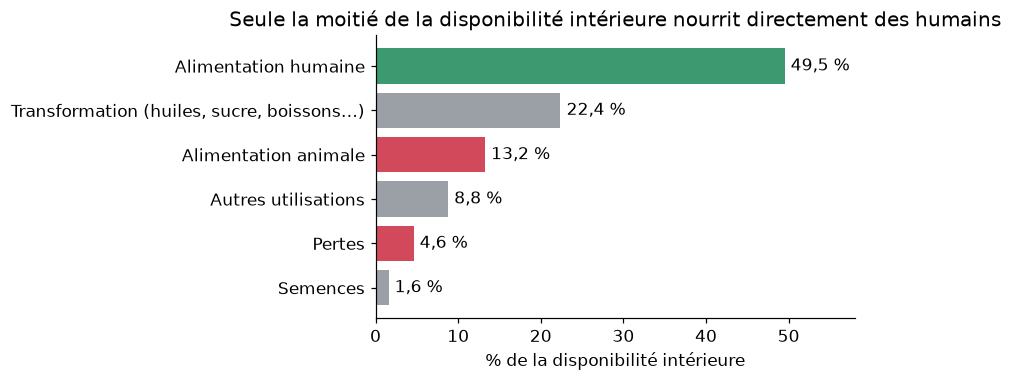

In [6]:
uses = an.q4_uses(d)
display(uses.assign(Part=uses["Part"].map(an.pct)))

fig, ax = plt.subplots(figsize=(8, 3.6))
colors = [GREEN if u == "Alimentation humaine" else RED if u in ("Alimentation animale", "Pertes") else GREY for u in uses["Utilisation"]]
bars = ax.barh(uses["Utilisation"], uses["Part"] * 100, color=colors)
ax.bar_label(bars, labels=[an.pct(p) for p in uses["Part"]], padding=4)
ax.invert_yaxis(); ax.set_xlabel("% de la disponibilité intérieure"); ax.set_xlim(0, 58)
ax.set_title("Seule la moitié de la disponibilité intérieure nourrit directement des humains")
plt.tight_layout(); plt.show()

In [7]:
cer = an.q4_cereals(d)
print("Céréales :", ", ".join(f"{u} {an.pct(p)}" for u, p in zip(cer["Utilisation"], cer["Part"])))

Céréales : Alimentation humaine 42,8 %, Alimentation animale 36,3 %


**➜ Sur la disponibilité intérieure mondiale :**
- **49,5 %** sert à l'**alimentation humaine** ;
- **13,2 %** sert à nourrir les **animaux** (et **36 % des céréales** !) ;
- **4,6 %** est **perdue** ;
- le reste est transformé (huiles, sucre, boissons…), semé ou utilisé autrement.

## 6. Q5 — Les pays les plus touchés en 2017

,Zone,sous_alimentes,proportion
0,Haïti,"5,3 M","48,3 %"
1,République populaire démocratique de Corée,"12,0 M","47,2 %"
2,Madagascar,"10,5 M","41,1 %"
3,Libéria,"1,8 M","38,3 %"
4,Lesotho,"0,8 M","38,2 %"
5,Tchad,"5,7 M","38,0 %"
6,Rwanda,"4,2 M","35,1 %"
7,Mozambique,"9,4 M","32,8 %"
8,Timor-Leste,"0,4 M","32,2 %"
9,Afghanistan,"10,5 M","28,9 %"


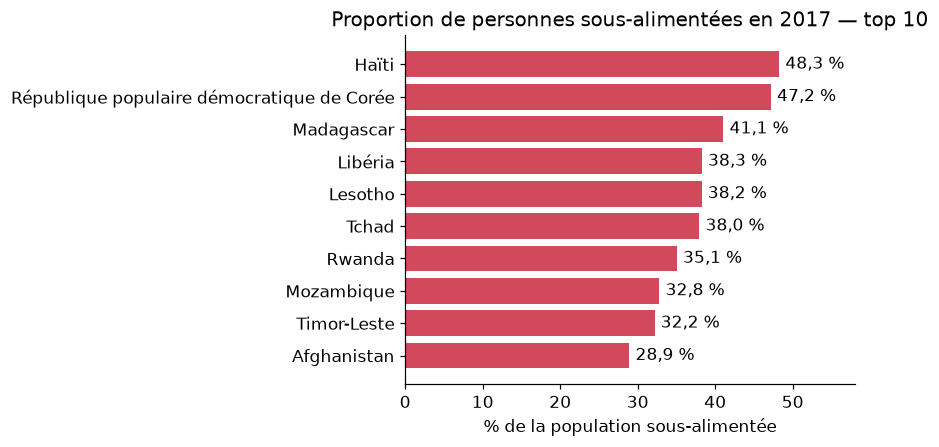

In [8]:
top = an.q5_highest_proportion(d)
display(top.assign(proportion=top["proportion"].map(an.pct),
                   sous_alimentes=(top["sous_alimentes"] / 1e6).map(lambda x: an.fr(x, 1) + " M")).drop(columns="population"))

fig, ax = plt.subplots(figsize=(8, 4.2))
bars = ax.barh(top["Zone"], top["proportion"] * 100, color=RED)
ax.bar_label(bars, labels=[an.pct(p) for p in top["proportion"]], padding=4)
ax.invert_yaxis(); ax.set_xlabel("% de la population sous-alimentée"); ax.set_xlim(0, 58)
ax.set_title("Proportion de personnes sous-alimentées en 2017 — top 10")
plt.tight_layout(); plt.show()

**➜ En Haïti, près d'une personne sur deux (48 %) est sous-alimentée**, suivie de la Corée du Nord (47 %) et de Madagascar (41 %).

💡 Si l'on avait remplacé `<0.1` par une valeur, de très petits pays comme la Dominique (≈ 70 000 habitants) seraient apparus en tête à tort.

## 7. Q6 — Les pays ayant reçu le plus d'aide alimentaire depuis 2013

,Zone,tonnes,part_aide_totale
0,République arabe syrienne,1 858 943,"16,8 %"
1,Éthiopie,1 381 294,"12,5 %"
2,Yémen,1 206 484,"10,9 %"
3,Soudan du Sud,695 248,"6,3 %"
4,Soudan,669 784,"6,1 %"
5,Kenya,552 836,"5,0 %"
6,Bangladesh,348 188,"3,2 %"
7,Somalie,292 678,"2,7 %"
8,République démocratique du Congo,288 502,"2,6 %"
9,Niger,276 344,"2,5 %"


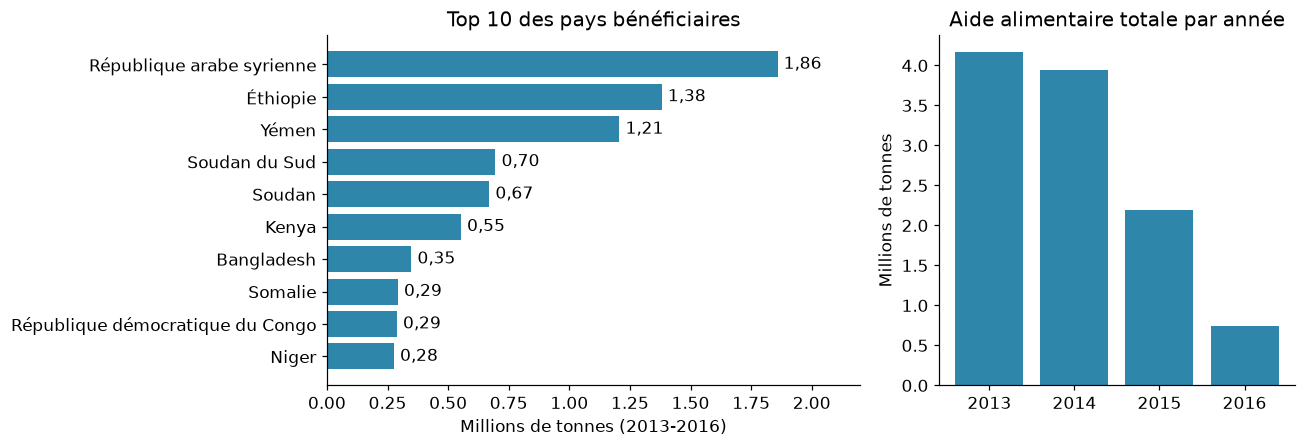

In [9]:
aid = an.q6_most_aid(d)
display(aid.assign(tonnes=aid["tonnes"].map(lambda x: an.fr(x, 0)), part_aide_totale=aid["part_aide_totale"].map(an.pct)))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), gridspec_kw={"width_ratios": [3, 2]})
bars = axes[0].barh(aid["Zone"], aid["tonnes"] / 1e6, color=BLUE)
axes[0].bar_label(bars, labels=[an.fr(t / 1e6, 2) for t in aid["tonnes"]], padding=4)
axes[0].invert_yaxis(); axes[0].set_xlabel("Millions de tonnes (2013-2016)"); axes[0].set_xlim(0, 2.2)
axes[0].set_title("Top 10 des pays bénéficiaires")
year = an.aid_by_year(d)
axes[1].bar(year["Année"].astype(str), year["tonnes"] / 1e6, color=BLUE)
axes[1].set_title("Aide alimentaire totale par année"); axes[1].set_ylabel("Millions de tonnes")
plt.tight_layout(); plt.show()

**➜ La Syrie a reçu à elle seule 17 % de l'aide alimentaire mondiale (1,86 million de tonnes)**, devant l'Éthiopie et le Yémen.
Les trois premiers pays concentrent près de 40 % de l'aide : elle va surtout aux pays en **guerre ou en crise humanitaire**,
pas forcément à ceux où la proportion de sous-alimentés est la plus forte (Haïti n'est pas dans le top 10).

Le volume total d'aide baisse fortement entre 2013 et 2016 (de 4,2 à 0,7 million de tonnes) : la chute de 2016 peut aussi venir de données incomplètes pour cette année.

## 8. Q7 — Plus ou moins de nourriture par habitant

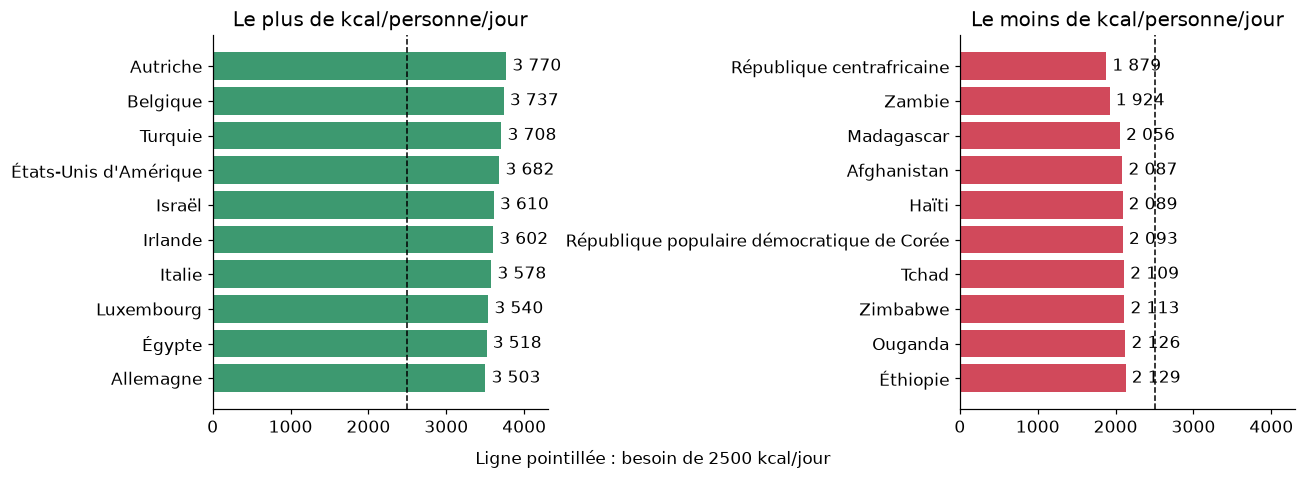

In [10]:
most, least = an.q7_availability(d)
fig, axes = plt.subplots(1, 2, figsize=(12, 4.2), sharex=True)
for ax, df, color, title in [(axes[0], most, GREEN, "Le plus de kcal/personne/jour"), (axes[1], least, RED, "Le moins de kcal/personne/jour")]:
    bars = ax.barh(df["Zone"], df["kcal"], color=color)
    ax.bar_label(bars, labels=[an.fr(k, 0) for k in df["kcal"]], padding=4)
    ax.axvline(an.KCAL_NEED, color="black", linestyle="--", linewidth=1)
    ax.invert_yaxis(); ax.set_title(title); ax.set_xlim(0, 4300)
fig.text(0.5, -0.02, f"Ligne pointillée : besoin de {an.KCAL_NEED} kcal/jour", ha="center")
plt.tight_layout(); plt.show()

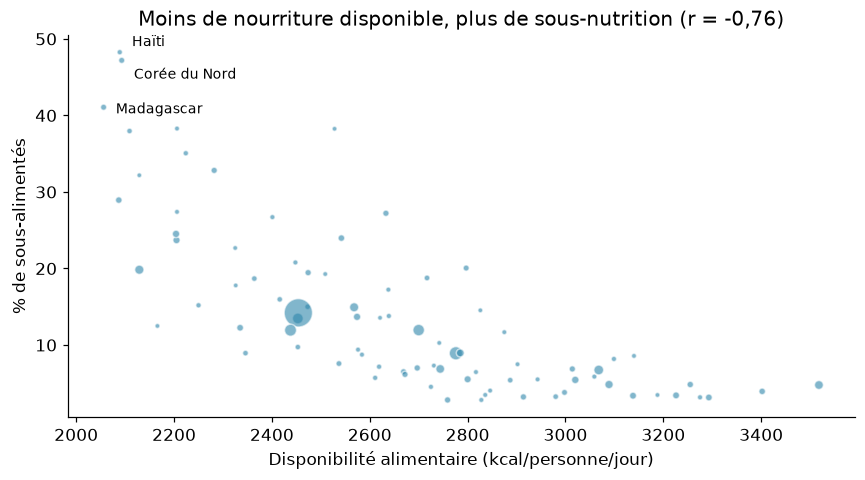

In [11]:
rel = an.availability_vs_undernourishment(d)
r = rel["kcal"].corr(rel["proportion"])
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(rel["kcal"], rel["proportion"] * 100, s=rel["population"] / 4e6 + 10, alpha=0.6, color=BLUE, edgecolor="white")
labels = {"Haïti": (8, 4), "République populaire démocratique de Corée": (8, -12), "Madagascar": (8, -4)}
for _, row in rel[rel["Zone"].isin(labels)].iterrows():
    name = "Corée du Nord" if "Corée" in row["Zone"] else row["Zone"]
    ax.annotate(name, (row["kcal"], row["proportion"] * 100), xytext=labels[row["Zone"]], textcoords="offset points", fontsize=9)
ax.set_xlabel("Disponibilité alimentaire (kcal/personne/jour)"); ax.set_ylabel("% de sous-alimentés")
ax.set_title(f"Moins de nourriture disponible, plus de sous-nutrition (r = {an.fr(r, 2)})")
plt.tight_layout(); plt.show()

**➜ Un Autrichien dispose en moyenne de 3 770 kcal par jour, deux fois plus qu'un habitant de République centrafricaine (1 879 kcal).**
Les pays les moins bien pourvus sont sous le besoin de 2 500 kcal, et ce sont souvent les mêmes que ceux qui comptent le plus de sous-alimentés.

## 9. Conclusion

| Question | Réponse |
|---|---|
| Q1 · Proportion de sous-alimentés (2017) | **7,1 %** de la population mondiale, ~536 millions de personnes |
| Q2 · Personnes nourries par la disponibilité mondiale | **8,37 milliards** (111 %), hypothèse 2 500 kcal/jour |
| Q3 · Idem, produits végétaux seuls | **6,90 milliards** (91 %) |
| Q4 · Utilisation de la disponibilité intérieure | 49,5 % alimentation humaine · 13,2 % animale · 4,6 % pertes |
| Q5 · Pays les plus touchés | Haïti (48 %), Corée du Nord (47 %), Madagascar (41 %) |
| Q6 · Pays les plus aidés depuis 2013 | Syrie (1,86 Mt), Éthiopie (1,38 Mt), Yémen (1,21 Mt) |
| Q7 · Disponibilité par habitant | + : Autriche (3 770 kcal) · − : République centrafricaine (1 879 kcal) |

**Le monde produit assez pour nourrir tout le monde : la faim est d'abord un problème de répartition**,
aggravé par l'utilisation d'une partie des céréales pour nourrir les animaux, par les pertes, et par les crises qui orientent l'aide alimentaire.